# Graph object load

In [1]:
import cdlib
import networkx as nx

In [41]:
# Get graph
output_dir = "/Users/htang/Documents/PhD/Project - CAS/C3_Microbiome/2019-10-24_QIIME_CAS_COAST_meta_5/" + \
    "output/2020-09-25_fastspar_community/"
g = nx.readwrite.read_gml(path=output_dir + "net.graph.all.pos.txt", 
                         label="name")
g

# Community discovery

In [3]:
from cdlib import algorithms

In [4]:
# Louvain
# Uses python louvain implementation
louvain_coms = algorithms.louvain(g, resolution=1)

In [5]:
# Leiden
leiden_coms = algorithms.leiden(g)

In [6]:
# NodeClustering object properties
# clustering algorithm name
leiden_coms.method_name 

'Leiden'

In [7]:
# clustering parameters
leiden_coms.method_parameters 

{'initial_membership': None, 'weights': None}

In [8]:
# Identified clustering - nodes arranged in subsets
leiden_coms.communities 

[[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33],
 [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21],
 [23, 24, 25, 27, 28, 31],
 [4, 5, 6, 10, 16]]

In [9]:
# Whether clustering is overlapping or not
leiden_coms.overlap

False

In [10]:
# % nodes covered by clustering
leiden_coms.node_coverage

1.0

In [11]:
# JSON representation of results
leiden_coms.to_json()

'{"communities": [[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33], [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21], [23, 24, 25, 27, 28, 31], [4, 5, 6, 10, 16]], "algorithm": "Leiden", "params": {"initial_membership": null, "weights": null}, "overlap": false, "coverage": 1.0}'

# Clustering evaluation (fitness functions)

In [12]:
# For each index: min/max/mean/std
# Average across all communities
leiden_coms.average_internal_degree()

FitnessResult(min=2.3333333333333335, max=4.181818181818182, score=3.103787878787879, std=0.7758948002447444)

In [13]:
# Values for each community
leiden_coms.average_internal_degree(summary=False)

[3.5, 4.181818181818182, 2.3333333333333335, 2.4]

In [14]:
# Alternative syntax, at library level
from cdlib import evaluation
evaluation.average_internal_degree(g, leiden_coms)

FitnessResult(min=2.3333333333333335, max=4.181818181818182, score=3.103787878787879, std=0.7758948002447444)

# Clustering evaluation (comparison)

In [15]:
# CDlib allows to do so by exposing several clustering resemblance scores, 
# each one of them tailored to support specific kind of network clusterings 
# (crisp/partition, complete/partial node coverage).

# Evaluating mutual information
# Mutual information is the reduction in uncertainty about variable X , 
# or the expected reduction in the number of yes/no questions needed to guess X after observing Y .
# http://www.scholarpedia.org/article/Mutual_information

# Adjusted MI: for two clusterings U and V
# AMI(U, V) = [MI(U, V) - E(MI(U, V))] / [max(H(U), H(V)) - E(MI(U, V))]
# where H(X) = -E_(P_X) log(P_X)
# and MI(X, Y) = H(X) - H(X|Y) 

# Normalised MI: normalization of MI to scale results between 0 (no mutual information) and 1 (perfect correlation)
# Normalized by sqrt(H(labels_true) * H(labels_pred)) i.e. sqrt(H(X)*H(Y))
leiden_coms.normalized_mutual_information(lp_coms)

MatchingResult(score=0.5421597004371672, std=None)

In [16]:
# Alternative mutual information
evaluation.normalized_mutual_information(lp_coms, leiden_coms)

MatchingResult(score=0.5421597004371672, std=None)

# Community and statistics visualisation

## Graph visualisation

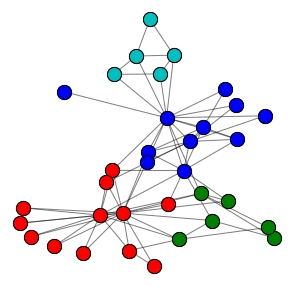

In [17]:
from cdlib import viz
pos = nx.spring_layout(g)
viz.plot_network_clusters(g, leiden_coms, pos, figsize=(5, 5))

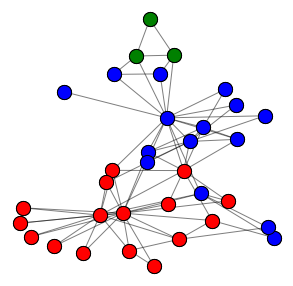

In [18]:
viz.plot_network_clusters(g, lp_coms, pos, figsize=(5,5))

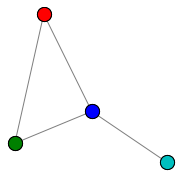

In [19]:
# Collapsing community nodes into single met-node for medium/large graphs 
viz.plot_community_graph(g, leiden_coms, figsize=(3,3))

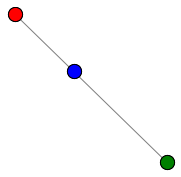

In [20]:
viz.plot_community_graph(g, lp_coms, figsize=(3,3))

## Community fitness/comparison visualization

/opt/anaconda3/envs/igraph-work/lib/python3.8/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


<AxesSubplot:xlabel='Algorithm', ylabel='internal_edge_density'>

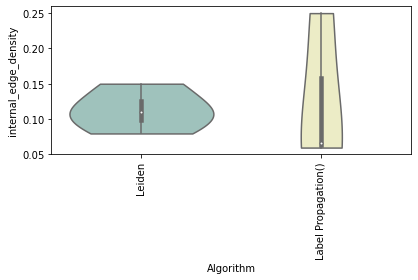

In [21]:
# Violin plots to visualize how given fitness function distributes over communities
# E.g. internal edge density:
# f(S) = m_s/(n_s(n_s - 1)/2) where m_s is number of community internal edges and n_S is number of community nodes 
# in community set S 
viz.plot_com_stat([leiden_coms, lp_coms], evaluation.internal_edge_density)

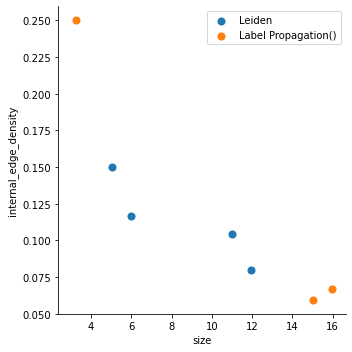

In [22]:
# Scatterplot to compare pair-wise fitness functions for one or more clusterings
viz.plot_com_properties_relation([leiden_coms, lp_coms], evaluation.size, evaluation.internal_edge_density)

<AxesSubplot:xlabel='graph', ylabel='score'>

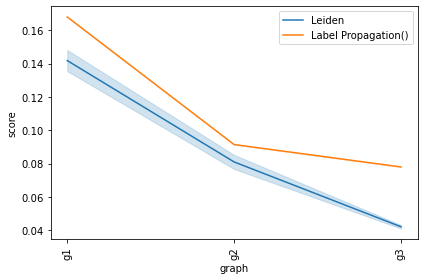

In [23]:
from cdlib import NodeClustering
import networkx as nx

# Generate graphs of 1000 nodes, 
# power law exponent = 3 for degree distribution,
# power law exponent = 1.5 for community size distribution
# Varying mu = fraction of intra-community edges incident to each node. 
# This value must be in the interval [0, 1].

g1 = nx.generators.community.LFR_benchmark_graph(1000, 3, 1.5, 0.5, min_community=20, average_degree=5)
g2 = nx.generators.community.LFR_benchmark_graph(1000, 3, 1.5, 0.6, min_community=20, average_degree=5)
g3 = nx.generators.community.LFR_benchmark_graph(1000, 3, 1.5, 0.7, min_community=20, average_degree=5)

names = ["g1", "g2", "g3"]
graphs = [g1, g2, g3]
references = []

# building the NodeClustering ground truth for the graphs
for g in graphs:
    ground_truth = NodeClustering(communities={frozenset(g.nodes[v]['community']) for v in g}, graph=g, method_name="reference")
    references.append(ground_truth)
    
algos = [algorithms.leiden, algorithms.label_propagation]

# Computing the visualization (2 execution per method, NMI as scoring for ground truth resemblance)
viz.plot_scoring(graphs, references, names, algos, scoring=evaluation.adjusted_mutual_information, nbRuns=2)

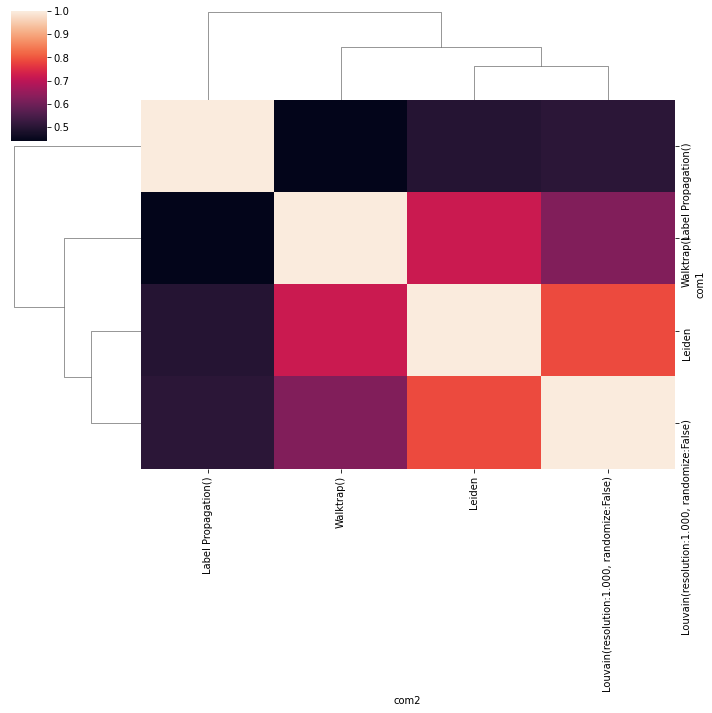

In [25]:
# Compare clusterings with Karate Club graph
import infomap
g = nx.karate_club_graph()

lp_coms = algorithms.label_propagation(g)
louvain_coms = algorithms.louvain(g)
leiden_coms = algorithms.leiden(g)
wp_coms = algorithms.walktrap(g)
# infomap_coms = algorithms.infomap(g)

viz.plot_sim_matrix([leiden_coms, louvain_coms, lp_coms, wp_coms],evaluation.adjusted_mutual_information)

# Pooling

In [26]:
# Stack execution of multiple algorithms
from cdlib import ensemble

# Louvain configuration
methods = [algorithms.louvain, algorithms.leiden]

for coms in ensemble.pool(g, methods, configurations=[[], []]):
    print(coms.method_name, "\n", coms.communities)

Louvain 
 [[8, 14, 15, 18, 20, 22, 23, 26, 27, 29, 30, 32, 33], [0, 1, 2, 3, 7, 9, 11, 12, 13, 17, 19, 21], [4, 5, 6, 10, 16], [24, 25, 28, 31]]
Leiden 
 [[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33], [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21], [23, 24, 25, 27, 28, 31], [4, 5, 6, 10, 16]]


In [28]:
# Configuration parameter allows definition of parameters for each algorithm
# Example of Louvain configuration
resolution = ensemble.Parameter(name="resolution", start=0.1)
randomize = ensemble.BoolParameter(name="randomize", value=True)
louvain_conf = [resolution, randomize]
# Conditions should give similar clusterings to leiden

methods = [algorithms.louvain, algorithms.leiden]

for communities in ensemble.pool(g, methods, [louvain_conf, []]):
    print(coms.method_name, "\n", coms.communities)

Leiden 
 [[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33], [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21], [23, 24, 25, 27, 28, 31], [4, 5, 6, 10, 16]]
Leiden 
 [[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33], [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21], [23, 24, 25, 27, 28, 31], [4, 5, 6, 10, 16]]


In [32]:
# Grid ranges
resolution = ensemble.Parameter(name="resolution", start=0.7, end=1, step=0.1) # numeric range
randomize = ensemble.BoolParameter(name="randomize") # boolean range [True, False]
louvain_conf = [resolution, randomize]
methods = [algorithms.louvain, algorithms.leiden]

for communities in ensemble.pool(g, methods, [louvain_conf, []]):
    print(coms.method_name, "\n", coms.communities)

Leiden 
 [[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33], [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21], [23, 24, 25, 27, 28, 31], [4, 5, 6, 10, 16]]
Leiden 
 [[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33], [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21], [23, 24, 25, 27, 28, 31], [4, 5, 6, 10, 16]]
Leiden 
 [[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33], [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21], [23, 24, 25, 27, 28, 31], [4, 5, 6, 10, 16]]
Leiden 
 [[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33], [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21], [23, 24, 25, 27, 28, 31], [4, 5, 6, 10, 16]]
Leiden 
 [[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33], [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21], [23, 24, 25, 27, 28, 31], [4, 5, 6, 10, 16]]
Leiden 
 [[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33], [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21], [23, 24, 25, 27, 28, 31], [4, 5, 6, 10, 16]]
Leiden 
 [[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33], [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21], [23, 24, 25, 27, 28, 31], [4, 5, 6, 1

In [33]:
# Grid Execution takes care to instantiate a CD algorithm with all the possible combination of parameter values 
# (cartesian product) as expressed by the ranges passed as input.

resolution = ensemble.Parameter(name="resolution", start=0.7, end=1, step=0.1)

for coms in ensemble.grid_execution(graph=g, method=algorithms.louvain, parameters=[resolution]):
    print(coms.method_name, coms.method_parameters, "\n", coms.communities, "\n")

Louvain {'weight': 'weight', 'resolution': 0.7, 'randomize': False} 
 [[0, 1, 2, 3, 7, 9, 11, 12, 13, 17, 19, 21], [8, 14, 15, 18, 20, 22, 30, 32, 33], [4, 5, 6, 10, 16], [23, 26, 27, 29], [24, 25, 28, 31]] 

Louvain {'weight': 'weight', 'resolution': 0.7999999999999999, 'randomize': False} 
 [[8, 14, 15, 18, 20, 22, 23, 26, 27, 29, 30, 32, 33], [0, 1, 2, 3, 7, 9, 11, 12, 13, 17, 19, 21], [4, 5, 6, 10, 16], [24, 25, 28, 31]] 

Louvain {'weight': 'weight', 'resolution': 0.8999999999999999, 'randomize': False} 
 [[8, 14, 15, 18, 20, 22, 23, 26, 27, 29, 30, 32, 33], [0, 1, 2, 3, 7, 9, 11, 12, 13, 17, 19, 21], [4, 5, 6, 10, 16], [24, 25, 28, 31]] 

Louvain {'weight': 'weight', 'resolution': 0.9999999999999999, 'randomize': False} 
 [[8, 14, 15, 18, 20, 22, 23, 26, 27, 29, 30, 32, 33], [0, 1, 2, 3, 7, 9, 11, 12, 13, 17, 19, 21], [4, 5, 6, 10, 16], [24, 25, 28, 31]] 



## Optimisation (identifying optimal clusterings)

In [34]:
# Grid search
# Grid search will execute all the possible configuration as expressed by the method parameters 
# and return only the optimal partition w.r.t. the specified fitness function 
# (ER modularity in our example) and aggregation function (we want to maximize the fitness score).

resolution = ensemble.Parameter(name="resolution", start=0.1, end=1, step=0.1)
randomize = ensemble.BoolParameter(name="randomize")

coms, scoring = ensemble.grid_search(graph=g, method=algorithms.louvain,
                                                     parameters=[resolution, randomize],
                                                     quality_score=evaluation.erdos_renyi_modularity,
                                                     aggregate=max)

print("Communities:\n %s \nConfiguration: %s \nScoring: %s" %(coms.communities, coms.method_parameters, scoring))

Communities:
 [[8, 14, 15, 18, 20, 22, 23, 26, 27, 29, 30, 32, 33], [0, 1, 2, 3, 7, 9, 11, 12, 13, 17, 19, 21], [4, 5, 6, 10, 16], [24, 25, 28, 31]] 
Configuration: {'weight': 'weight', 'resolution': 0.8, 'randomize': False} 
Scoring: FitnessResult(min=None, max=None, score=0.4712052653229123, std=None)


In [35]:
# Random search optimisation strategy
# (controlled through instances parameter)

communities, scoring = ensemble.random_search(graph=g, method=algorithms.louvain,
                                                       parameters=[resolution, randomize],
                                                       quality_score=evaluation.erdos_renyi_modularity,
                                                       instances=5, aggregate=max)

print("Communities:\n %s \nConfiguration: %s \nScoring: %s" %(coms.communities, coms.method_parameters, scoring))

Communities:
 [[8, 14, 15, 18, 20, 22, 23, 26, 27, 29, 30, 32, 33], [0, 1, 2, 3, 7, 9, 11, 12, 13, 17, 19, 21], [4, 5, 6, 10, 16], [24, 25, 28, 31]] 
Configuration: {'weight': 'weight', 'resolution': 0.8, 'randomize': False} 
Scoring: FitnessResult(min=None, max=None, score=0.47051967640202935, std=None)


In [36]:
# Combine pooling and optimisation to get only optimal results for all algorithms

louvain_conf = [resolution, randomize]

epsilon = ensemble.Parameter(name="epsilon", start=0.2, end=0.7, step=0.1)
demon_conf = [epsilon]

methods = [algorithms.louvain, algorithms.demon]

for coms, scoring in ensemble.pool_grid_filter(g, methods, [louvain_conf, demon_conf], \
                                               quality_score=evaluation.erdos_renyi_modularity, aggregate=max):
    print("%s\nCommunities:\n %s \nConfiguration: %s \nScoring: %s\n" \
          %(coms.method_name, coms.communities, coms.method_parameters, scoring))

Louvain
Communities:
 [[8, 14, 15, 18, 20, 22, 23, 26, 27, 29, 30, 32, 33], [0, 1, 2, 3, 7, 9, 11, 12, 13, 17, 19, 21], [4, 5, 6, 10, 16], [24, 25, 28, 31]] 
Configuration: {'weight': 'weight', 'resolution': 0.8, 'randomize': False} 
Scoring: FitnessResult(min=None, max=None, score=0.4712052653229123, std=None)

DEMON
Communities:
 [[2, 8, 14, 15, 18, 20, 22, 23, 26, 27, 29, 30, 31, 32, 33], [8, 14, 15, 18, 20, 22, 23, 26, 27, 28, 29, 30, 31, 32, 33], [0, 1, 2, 3, 7, 8, 12, 13, 17, 19, 21, 30, 32, 33], [0, 4, 5, 6, 10, 16]] 
Configuration: {'epsilon': 0.5000000000000001, 'min_com_size': 3} 
Scoring: FitnessResult(min=None, max=None, score=0.757232963115316, std=None)

